In [47]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("la_sales.sqlite")

EXTRACT From Data Sources

- Flat files: read_csv(), read_json(), read_parquet()
    -Append multiple files
-Databases - pd.read_sql() + sqlalchemy
-APIs - tap into web based resources

In [48]:
# Extract Flat Files
sales_df = pd.read_csv("LA_Retail_Sales.csv")
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          750 non-null    object 
 1   store_name        750 non-null    object 
 2   product_category  750 non-null    object 
 3   date              750 non-null    object 
 4   Unit sales        745 non-null    float64
 5   DOLLAR SALES      743 non-null    float64
 6   store_zip         750 non-null    object 
 7   promotion_flag    750 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 41.9+ KB


In [49]:

import glob

file_paths = glob.glob("LA_Retail_Sales_By_Day/*.csv") # Use the wildcard to grab all files in the folder

# Concat all sales cvs files into one
sales_df = pd.concat([pd.read_csv(fp) for fp in file_paths], ignore_index = True)

sales_df.info() # Now we've combined the 30 files into one, and get the same result as above

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          750 non-null    object 
 1   store_name        750 non-null    object 
 2   product_category  750 non-null    object 
 3   date              750 non-null    object 
 4   unit_sales        745 non-null    float64
 5   dollar_sales      743 non-null    float64
 6   store_zip         750 non-null    object 
 7   promotion_flag    750 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 41.9+ KB


In [50]:
# If you only wanted a few days of data

sales_df = pd.DataFrame()

for day in range(1,6):
    print("day:", day)
    day_df = pd.read_csv(f"LA_Retail_Sales_By_Day/sales_2024-09-{day:02d}.csv")
    sales_df = pd.concat([sales_df, day_df])
    print("length:", len(sales_df))

sales_df.head()

day: 1
length: 30
day: 2
length: 57
day: 3
length: 81
day: 4
length: 97
day: 5
length: 120


,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA008,Store_8,Produce,2024-09-01,4.0,79.99,90001,False
3,LA010,Store_10,Beverages,2024-09-01,22.0,140.45,90005,True
4,LA006,Store_6,Snacks,2024-09-01,17.0,50.03,90003,False


In [51]:
# Read as a json file

sales_df = pd.read_json("LA_Retail_Sales.json", lines=True)

sales_df.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA004,Store_4,Produce,2024-09-15,18.0,298.26,90003,True
3,LA003,Store_3,Household,2024-09-07,7.0,25.69,90001,True
4,LA008,Store_8,Beverages,2024-09-18,25.0,85.46,90005,False


In [52]:
# Read in a parquet

sales_df = pd.read_parquet("LA_Retail_Sales.parquet")

sales_df.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA004,Store_4,Produce,2024-09-15,18.0,298.26,90003,True
3,LA003,Store_3,Household,2024-09-07,7.0,25.69,90001,True
4,LA008,Store_8,Beverages,2024-09-18,25.0,85.46,90005,False


In [53]:
# Read in SQL

pd.read_sql("SELECT * FROM Sales", con=conn)

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag,rev_per_unit,temp
0,LA002,Store_2,Household,2024-09-01 00:00:00,16,96.28,90004,1,6.02,73.85
1,LA001,Store_1,Beverages,2024-09-01 00:00:00,14,86.63,90004,1,6.19,73.85
2,LA004,Store_4,Produce,2024-09-15 00:00:00,18,298.26,90003,1,16.57,65.12
3,LA003,Store_3,Household,2024-09-07 00:00:00,7,25.69,90001,1,3.67,82.00
4,LA008,Store_8,Beverages,2024-09-18 00:00:00,25,85.46,90005,0,3.42,61.16
...,...,...,...,...,...,...,...,...,...,...
733,LA010,Store_10,Beverages,2024-09-24 00:00:00,46,790.99,90005,1,17.20,69.10
734,LA008,Store_8,Snacks,2024-09-14 00:00:00,23,375.40,90003,0,16.32,66.11
735,LA004,Store_4,Personal Care,2024-09-14 00:00:00,17,225.24,90000,0,13.25,66.11
736,LA009,Store_9,Snacks,2024-09-28 00:00:00,37,406.47,90004,0,10.99,64.04


<Axes: xlabel='store_id'>

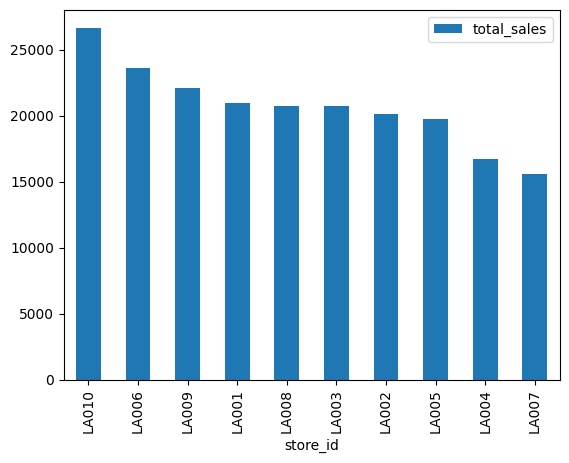

In [54]:
pd.read_sql('''
    SELECT store_id, sum(dollar_sales) as total_sales
    FROM Sales
    GROUP BY store_id
    ORDER BY total_sales DESC     
''', con=conn).set_index("store_id").plot.bar()



In [55]:
# Extract from an API

import requests
import time
from datetime import datetime
import os
from dotenv import load_dotenv

load_dotenv(".env")
API_KEY = os.getenv("API_KEY")
LAT, LON = 34.0522, -118.2437 # Coordinates for LA

unix_timestamp = int(datetime.strptime(str(sales_df["date"][0].date()),"%Y-%m-%d").timestamp())

url = (
    f"https://api.openweathermap.org/data/3.0/onecall/timemachine"
    f"?lat={LAT}&lon={LON}&dt={unix_timestamp}&appid={API_KEY}&units=imperial"
)

test_response = requests.get(url)


In [56]:
test_response.json()

{'lat': 34.0522,
 'lon': -118.2437,
 'timezone': 'America/Los_Angeles',
 'timezone_offset': -25200,
 'data': [{'dt': 1725166800,
   'sunrise': 1725110786,
   'sunset': 1725157213,
   'temp': 73.85,
   'feels_like': 74.26,
   'pressure': 1013,
   'humidity': 71,
   'dew_point': 63.86,
   'clouds': 0,
   'wind_speed': 3.06,
   'wind_deg': 153,
   'weather': [{'id': 800,
     'main': 'Clear',
     'description': 'clear sky',
     'icon': '01n'}]}]}

In [57]:
data = test_response.json()

data["data"] # now you're working in the data field

[{'dt': 1725166800,
  'sunrise': 1725110786,
  'sunset': 1725157213,
  'temp': 73.85,
  'feels_like': 74.26,
  'pressure': 1013,
  'humidity': 71,
  'dew_point': 63.86,
  'clouds': 0,
  'wind_speed': 3.06,
  'wind_deg': 153,
  'weather': [{'id': 800,
    'main': 'Clear',
    'description': 'clear sky',
    'icon': '01n'}]}]

In [58]:
data["data"][0]['temp']# the [0] gets rid of the brackets. Then you can call the temp

73.85

GRAB ACTUAL API DATA

In [59]:
weather_data = []
dates = sales_df["date"].sort_values().dropna().unique()

# Logic to call API and fill weather data here

for date in dates:
    unix_timestamp = int(datetime.strptime(str(date.date()), "%Y-%m-%d").timestamp())

    url = (
        f"https://api.openweathermap.org/data/3.0/onecall/timemachine"
        f"?lat={LAT}&lon={LON}&dt={unix_timestamp}&appid={API_KEY}&units=imperial"
    )
    
    response = requests.get(url)
    if response.status_code == 200:
        data = response.json()
        day_weather = {
            "date" : date.date(),
            "temp" : data["data"][0]["temp"],
            "humidity": data["data"][0]["humidity"],
            "weather_main": data["data"][0]["weather"][0]["main"], # going on level deeper for this field
            "weather_main": data["data"][0]["weather"][0]["description"]
        }
        weather_data.append(day_weather)
    else:
        print(f"Failed to fetch data for {date.date()}: {response.status_code}")
        
    time.sleep(1)


weather_df = pd.DataFrame(weather_data)

In [60]:
weather_df.head()

,date,temp,humidity,weather_main
0,2024-09-01,73.85,71,clear sky
1,2024-09-02,71.46,74,clear sky
2,2024-09-03,75.87,76,clear sky
3,2024-09-04,79.93,66,clear sky
4,2024-09-05,87.89,37,clear sky


TRANSFORM

In [61]:
# Transform the date column to a date

weather_df.info() # currently a date, we want this to be a datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          30 non-null     object 
 1   temp          30 non-null     float64
 2   humidity      30 non-null     int64  
 3   weather_main  30 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.1+ KB


In [62]:
# Now we transform
weather_df["date"] = pd.to_datetime(weather_df["date"])
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          30 non-null     datetime64[ns]
 1   temp          30 non-null     float64       
 2   humidity      30 non-null     int64         
 3   weather_main  30 non-null     object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.1+ KB


In [63]:
weather_df

,date,temp,humidity,weather_main
0,2024-09-01,73.85,71,clear sky
1,2024-09-02,71.46,74,clear sky
2,2024-09-03,75.87,76,clear sky
3,2024-09-04,79.93,66,clear sky
4,2024-09-05,87.89,37,clear sky
5,2024-09-06,92.59,23,few clouds
6,2024-09-07,82.00,46,clear sky
7,2024-09-08,84.20,56,clear sky
8,2024-09-09,89.49,33,clear sky
9,2024-09-10,87.89,28,clear sky


<Axes: xlabel='date'>

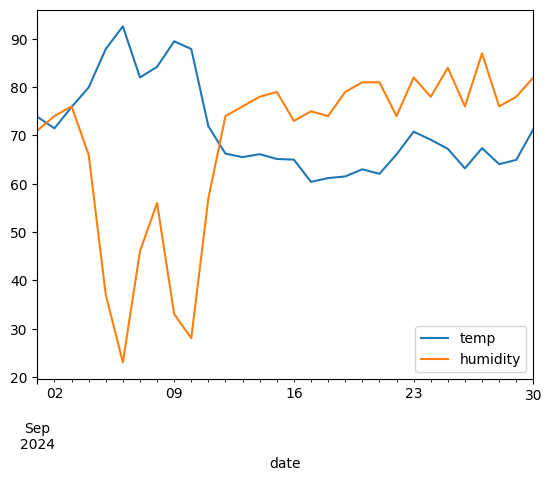

In [64]:
weather_df.set_index("date").plot.line()

In [65]:
sales_df = pd.read_csv("LA_Retail_Sales.csv")

# Transform to all lowercase, spaces become underscores

sales_df.columns = sales_df.columns.str.lower().str.replace(" ","_")

sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          750 non-null    object 
 1   store_name        750 non-null    object 
 2   product_category  750 non-null    object 
 3   date              750 non-null    object 
 4   unit_sales        745 non-null    float64
 5   dollar_sales      743 non-null    float64
 6   store_zip         750 non-null    object 
 7   promotion_flag    750 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 41.9+ KB


In [66]:
# This cell is for filling in non nulls on the unit_sales column. We will do something else instead

sales_df.query("unit_sales.isna()") # grabs the rows that are missing a unit_sales
missing_unit_indices = sales_df.query("unit_sales.isna()").index # grab the indices of those rows


'''
# Fill in those rows
sales_df["unit_sales"] = sales_df["unit_sales"].fillna(0)

sales_df.info()

'''


'\n# Fill in those rows\nsales_df["unit_sales"] = sales_df["unit_sales"].fillna(0)\n\nsales_df.info()\n\n'

In [67]:
# Drop the rows instead of filling them

sales_df = sales_df.dropna(subset=["unit_sales", "dollar_sales"])
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 738 entries, 0 to 749
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          738 non-null    object 
 1   store_name        738 non-null    object 
 2   product_category  738 non-null    object 
 3   date              738 non-null    object 
 4   unit_sales        738 non-null    float64
 5   dollar_sales      738 non-null    float64
 6   store_zip         738 non-null    object 
 7   promotion_flag    738 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 46.8+ KB


In [68]:
# Create a new column for revenue per unit, round to 2
sales_df["rev_per_unit"] = (sales_df["dollar_sales"] / sales_df["unit_sales"]).round(2)
sales_df.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag,rev_per_unit
0,LA002,Store_2,Household,9/1/24,16.0,96.28,90004,True,6.02
1,LA001,Store_1,Beverages,9/1/24,14.0,86.63,90004,True,6.19
2,LA004,Store_4,Produce,9/15/24,18.0,298.26,90003,True,16.57
3,LA003,Store_3,Household,9/7/24,7.0,25.69,90001,True,3.67
4,LA008,Store_8,Beverages,9/18/24,25.0,85.46,90005,False,3.42


In [69]:
# Fix Bad data

sales_df.store_zip.value_counts() # shows that we have some zip codes of 900XX

# lets assume we know that XX is supposed to be 00

sales_df["store_zip"] = sales_df["store_zip"].str.replace("XX", "00")

sales_df.store_zip.value_counts()

store_zip
90003    137
90004    133
90001    124
90005    122
90000    118
90002    104
Name: count, dtype: int64

In [70]:
# Shows that our date column is object, unit sales is a float. We can change those like this

sales_df["date"] = pd.to_datetime(sales_df["date"],format = 'mixed')
sales_df['unit_sales'] = sales_df['unit_sales'].astype(int)

sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 738 entries, 0 to 749
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   store_id          738 non-null    object        
 1   store_name        738 non-null    object        
 2   product_category  738 non-null    object        
 3   date              738 non-null    datetime64[ns]
 4   unit_sales        738 non-null    int64         
 5   dollar_sales      738 non-null    float64       
 6   store_zip         738 non-null    object        
 7   promotion_flag    738 non-null    bool          
 8   rev_per_unit      738 non-null    float64       
dtypes: bool(1), datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 52.6+ KB


In [71]:
sales_df.describe()

,date,unit_sales,dollar_sales,rev_per_unit
count,738,738.000000,738.000000,738.000000
mean,2024-09-15 11:46:20.487804928,25.636856,280.526016,10.944715
min,2024-09-01 00:00:00,1.000000,5.330000,2.030000
25%,2024-09-08 06:00:00,13.000000,105.955000,6.547500
50%,2024-09-16 00:00:00,26.000000,224.910000,10.830000
75%,2024-09-23 00:00:00,38.000000,409.212500,15.310000
max,2024-09-30 00:00:00,50.000000,980.000000,20.000000
std,NaN,14.353205,217.325468,5.133041


<Axes: ylabel='Frequency'>

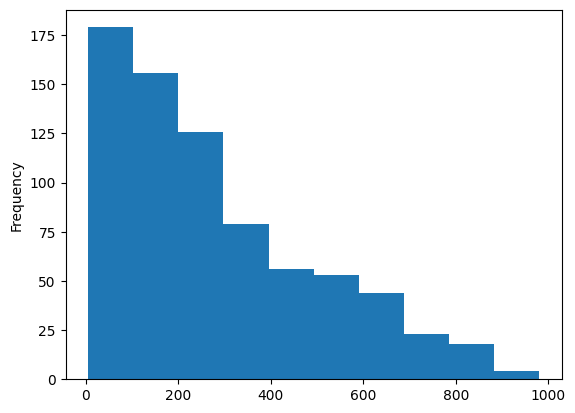

In [72]:
sales_df.dollar_sales.plot.hist()

MERGE API DATA

In [73]:
sales_df = sales_df.merge(weather_df[["date","temp"]], how = "left", on = "date")

LOAD INTO SQL

In [74]:
sales_df.to_sql("Sales", if_exists="replace", index=False, con= conn)

738

QUERY SQL

In [75]:
pd.read_sql("SELECT * FROM Sales Where temp > 70", con=conn)

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag,rev_per_unit,temp
0,LA002,Store_2,Household,2024-09-01 00:00:00,16,96.28,90004,1,6.02,73.85
1,LA001,Store_1,Beverages,2024-09-01 00:00:00,14,86.63,90004,1,6.19,73.85
2,LA003,Store_3,Household,2024-09-07 00:00:00,7,25.69,90001,1,3.67,82.00
3,LA004,Store_4,Beverages,2024-09-23 00:00:00,3,41.71,90004,0,13.90,70.77
4,LA009,Store_9,Household,2024-09-08 00:00:00,50,798.40,90001,1,15.97,84.20
...,...,...,...,...,...,...,...,...,...,...
310,LA009,Store_9,Produce,2024-09-09 00:00:00,22,364.55,90001,1,16.57,89.49
311,LA006,Store_6,Snacks,2024-09-02 00:00:00,16,99.57,90003,0,6.22,71.46
312,LA002,Store_2,Snacks,2024-09-11 00:00:00,2,23.38,90004,1,11.69,71.89
313,LA005,Store_5,Personal Care,2024-09-01 00:00:00,38,91.21,90004,0,2.40,73.85
